In [51]:
import pandas as pd
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
import os

In [52]:
train_df = pd.read_parquet('simplified_cayzn_train.parquet')
test_df = pd.read_parquet('simplified_cayzn_test.parquet')

In [53]:
print(train_df.columns)

Index(['sale_day_x', 'demand', 'price', 'od_origin_month', 'od_origin_weekday',
       'od_travel_time_minutes', 'origin_station_name',
       'destination_station_name', 'od_origin_time', 'time_series_id'],
      dtype='object')


In [ ]:
# 2. Préparer les features (seulement price et sale_day_x comme demandé)
features = ['price', 'sale_day_x','od_travel_time_minutes']
target = 'demand'

In [55]:
# Extraire X et y
X_train = train_df[features].values
y_train = train_df[target].values
X_test = test_df[features].values
y_test = test_df[target].values

In [56]:
print(f"\nFeatures utilisées: {features}")
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")


Features utilisées: ['price', 'sale_day_x']
X_train shape: (571914, 2)
y_train shape: (571914,)


In [57]:
# 3. Convertir directement en tenseurs PyTorch (pas de normalisation)
X_train_tensor = torch.FloatTensor(X_train)
y_train_tensor = torch.FloatTensor(y_train)
X_test_tensor = torch.FloatTensor(X_test)
y_test_tensor = torch.FloatTensor(y_test)

In [67]:
# 5. Définir le modèle TRÈS simple (juste 2 couches)
class SimpleDemandModel(nn.Module):
    def __init__(self, input_size=len(features)):
        super(SimpleDemandModel, self).__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            
            nn.Linear(128, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(128, 64),
            nn.ReLU(),    # 64 neurones -> 1 output (demand)
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            nn.ReLU()  # Garantit des sorties positives (plus smooth que ReLU)
        )
    
    def forward(self, x):
        return self.layers(x)


In [68]:
# 6. Créer le modèle
model = SimpleDemandModel()
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

print("\nModèle créé:")
print(model)


Modèle créé:
SimpleDemandModel(
  (layers): Sequential(
    (0): Linear(in_features=2, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=256, out_features=128, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.1, inplace=False)
    (9): Linear(in_features=128, out_features=64, bias=True)
    (10): ReLU()
    (11): Linear(in_features=64, out_features=32, bias=True)
    (12): ReLU()
    (13): Linear(in_features=32, out_features=1, bias=True)
    (14): ReLU()
  )
)


In [69]:
# 7. Entraîner le modèle
num_epochs = 50
batch_size = 32

# Créer des batches
dataset = torch.utils.data.TensorDataset(X_train_tensor, y_train_tensor)
dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)

print(f"\nEntraînement du modèle ({num_epochs} epochs)...")

for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    
    for batch_X, batch_y in dataloader:
        # Forward pass
        predictions = model(batch_X).squeeze()
        loss = criterion(predictions, batch_y)
        
        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    if (epoch + 1) % 20 == 0:
        avg_loss = total_loss / len(dataloader)
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}')


Entraînement du modèle (50 epochs)...
Epoch [20/50], Loss: 32.8454
Epoch [40/50], Loss: 32.3011


In [70]:
# 8. Évaluer le modèle
model.eval()
with torch.no_grad():
    # Prédictions sur le test set
    test_predictions = model(X_test_tensor).squeeze().numpy()

In [71]:
# 9. Calculer les métriques
rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
mae = mean_absolute_error(y_test, test_predictions)
print(f"\n=== RÉSULTATS ===")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")


=== RÉSULTATS ===
RMSE: 6.9989
MAE: 3.6799


In [72]:
# 📊 ENREGISTREMENT DES RÉSULTATS
timestamp = datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")
results_file = "training_results.csv"

# Créer un dictionnaire avec tous les résultats
result_data = {
    'timestamp': timestamp,
    'epochs': num_epochs,
    'batch_size': batch_size,
    'learning_rate': 0.001,
    'rmse': rmse,
    'mae': mae,
    'model_architecture': '2_layers_64_neurons'
}

# Vérifier si le fichier existe déjà
if os.path.exists(results_file):
    # Charger les résultats existants
    existing_results = pd.read_csv(results_file)
    # Ajouter le nouveau résultat
    new_result = pd.DataFrame([result_data])
    all_results = pd.concat([existing_results, new_result], ignore_index=True)
else:
    # Créer le premier enregistrement
    all_results = pd.DataFrame([result_data])

# Sauvegarder dans le fichier CSV
all_results.to_csv(results_file, index=False)

print(f"\n=== RÉSULTATS (Entraînement #{len(all_results)}) ===")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"📁 Résultats sauvegardés dans '{results_file}'")

# Afficher l'historique des 5 derniers entraînements
print(f"\n=== HISTORIQUE DES 5 DERNIERS ENTRAÎNEMENTS ===")
recent_results = all_results.tail(5)[['timestamp', 'epochs', 'rmse', 'mae']]
for idx, row in recent_results.iterrows():
    print(f"{row['timestamp']} | Epochs: {row['epochs']:2d} | RMSE: {row['rmse']:.4f} | MAE: {row['mae']:.4f}")

# Afficher les meilleures performances
best_rmse_idx = all_results['rmse'].idxmin()
best_mae_idx = all_results['mae'].idxmin()

print(f"\n=== MEILLEURES PERFORMANCES ===")
print(f"🏆 Meilleur RMSE: {all_results.loc[best_rmse_idx, 'rmse']:.4f} (#{best_rmse_idx+1}, {all_results.loc[best_rmse_idx, 'epochs']} epochs)")
print(f"🏆 Meilleur MAE: {all_results.loc[best_mae_idx, 'mae']:.4f} (#{best_mae_idx+1}, {all_results.loc[best_mae_idx, 'epochs']} epochs)")


=== RÉSULTATS (Entraînement #4) ===
RMSE: 6.9989
MAE: 3.6799
📁 Résultats sauvegardés dans 'training_results.csv'

=== HISTORIQUE DES 5 DERNIERS ENTRAÎNEMENTS ===
2025-07-14 13:43:06 | Epochs: 50 | RMSE: 6.8617 | MAE: 3.5648
2025-07-14 13:43:27 | Epochs: 50 | RMSE: 6.8181 | MAE: 3.4082
2025-07-15 11:59:36 | Epochs: 50 | RMSE: 6.8781 | MAE: 3.3901
2025-07-16 10:06:42 | Epochs: 50 | RMSE: 6.9989 | MAE: 3.6799

=== MEILLEURES PERFORMANCES ===
🏆 Meilleur RMSE: 6.8181 (#2, 50 epochs)
🏆 Meilleur MAE: 3.3901 (#3, 50 epochs)


In [73]:
# 10. Quelques prédictions d'exemple
print(f"\n=== EXEMPLES DE PRÉDICTIONS ===")
for i in range(5):
    actual = y_test[i]
    predicted = test_predictions[i]
    price = X_test[i, 0]
    sale_day = X_test[i, 1]
    print(f"Price: {price:.2f}, Sale_day: {sale_day:.0f} | Actual: {actual:.2f}, Predicted: {predicted:.2f}")

print(f"\nModèle entraîné avec succès! 🎉")


=== EXEMPLES DE PRÉDICTIONS ===
Price: 23.65, Sale_day: -89 | Actual: 0.00, Predicted: 0.75
Price: 23.65, Sale_day: -88 | Actual: 0.00, Predicted: 0.77
Price: 23.65, Sale_day: -87 | Actual: 0.00, Predicted: 0.78
Price: 23.65, Sale_day: -86 | Actual: 0.00, Predicted: 0.80
Price: 23.65, Sale_day: -85 | Actual: 0.00, Predicted: 0.81

Modèle entraîné avec succès! 🎉


In [74]:
# 10. Analyse détaillée des prédictions
print(f"\n=== ANALYSE DES PRÉDICTIONS ===")

# Calculer l'erreur absolue pour chaque prédiction
absolute_errors = np.abs(y_test - test_predictions)
relative_errors = np.abs(y_test - test_predictions) / (y_test + 1e-8)  # Éviter division par 0

# Trouver les meilleures et pires prédictions
best_indices = np.argsort(absolute_errors)[:5]  # 5 meilleures
worst_indices = np.argsort(absolute_errors)[-5:]  # 5 pires

print("🏆 TOP 5 MEILLEURES PRÉDICTIONS:")
for i, idx in enumerate(best_indices):
    actual = y_test[idx]
    predicted = test_predictions[idx]
    error = absolute_errors[idx]
    price = X_test[idx, 0]
    sale_day = X_test[idx, 1]
    print(f"{i+1}. Price: {price:.2f}, Sale_day: {sale_day:.0f} | Actual: {actual:.2f}, Predicted: {predicted:.2f} | Erreur: {error:.2f}")

print("\n💥 TOP 5 PIRES PRÉDICTIONS:")
for i, idx in enumerate(worst_indices):
    actual = y_test[idx]
    predicted = test_predictions[idx]
    error = absolute_errors[idx]
    price = X_test[idx, 0]
    sale_day = X_test[idx, 1]
    print(f"{i+1}. Price: {price:.2f}, Sale_day: {sale_day:.0f} | Actual: {actual:.2f}, Predicted: {predicted:.2f} | Erreur: {error:.2f}")

# Analyse par série temporelle (si time_series_id disponible)
if 'time_series_id' in test_df.columns:
    print(f"\n📊 ANALYSE PAR SÉRIE TEMPORELLE:")
    
    # Calculer l'erreur moyenne par série temporelle
    test_df_with_errors = test_df.copy()
    test_df_with_errors['predicted'] = test_predictions
    test_df_with_errors['absolute_error'] = absolute_errors
    
    series_performance = test_df_with_errors.groupby('time_series_id').agg({
        'absolute_error': 'mean',
        'demand': 'mean'
    }).reset_index()
    series_performance = series_performance.sort_values('absolute_error')
    
    # Meilleure série temporelle
    best_series_id = series_performance.iloc[0]['time_series_id']
    worst_series_id = series_performance.iloc[-1]['time_series_id']
    
    print(f"🏆 Meilleure série (ID: {best_series_id}): Erreur moyenne = {series_performance.iloc[0]['absolute_error']:.2f}")
    print(f"💥 Pire série (ID: {worst_series_id}): Erreur moyenne = {series_performance.iloc[-1]['absolute_error']:.2f}")
    
    # Montrer quelques prédictions de chaque série
    best_series_data = test_df_with_errors[test_df_with_errors['time_series_id'] == best_series_id].head(3)
    worst_series_data = test_df_with_errors[test_df_with_errors['time_series_id'] == worst_series_id].head(3)
    
    print(f"\n📈 Exemples de la MEILLEURE série (ID: {best_series_id}):")
    for _, row in best_series_data.iterrows():
        print(f"   Price: {row['price']:.2f}, Sale_day: {row['sale_day_x']:.0f} | Actual: {row['demand']:.2f}, Predicted: {row['predicted']:.2f}")
    
    print(f"\n📉 Exemples de la PIRE série (ID: {worst_series_id}):")
    for _, row in worst_series_data.iterrows():
        print(f"   Price: {row['price']:.2f}, Sale_day: {row['sale_day_x']:.0f} | Actual: {row['demand']:.2f}, Predicted: {row['predicted']:.2f}")

# Statistiques générales
print(f"\n📊 STATISTIQUES GÉNÉRALES:")
print(f"Erreur absolue moyenne: {np.mean(absolute_errors):.2f}")
print(f"Erreur absolue médiane: {np.median(absolute_errors):.2f}")
print(f"Erreur absolue max: {np.max(absolute_errors):.2f}")
print(f"Erreur absolue min: {np.min(absolute_errors):.2f}")

# Analyse par gamme de prix et de sale_day
print(f"\n💰 PERFORMANCE PAR GAMME DE PRIX:")
price_bins = np.percentile(X_test[:, 0], [0, 25, 50, 75, 100])
for i in range(len(price_bins)-1):
    mask = (X_test[:, 0] >= price_bins[i]) & (X_test[:, 0] < price_bins[i+1])
    if np.sum(mask) > 0:
        avg_error = np.mean(absolute_errors[mask])
        print(f"Prix {price_bins[i]:.0f}-{price_bins[i+1]:.0f}: Erreur moyenne = {avg_error:.2f} ({np.sum(mask)} échantillons)")

print(f"\n📅 PERFORMANCE PAR PÉRIODE DE VENTE:")
saleday_bins = np.percentile(X_test[:, 1], [0, 25, 50, 75, 100])
for i in range(len(saleday_bins)-1):
    mask = (X_test[:, 1] >= saleday_bins[i]) & (X_test[:, 1] < saleday_bins[i+1])
    if np.sum(mask) > 0:
        avg_error = np.mean(absolute_errors[mask])
        print(f"Sale_day {saleday_bins[i]:.0f} à {saleday_bins[i+1]:.0f}: Erreur moyenne = {avg_error:.2f} ({np.sum(mask)} échantillons)")

print(f"\nModèle entraîné avec succès! 🎉")


=== ANALYSE DES PRÉDICTIONS ===
🏆 TOP 5 MEILLEURES PRÉDICTIONS:
1. Price: 11.65, Sale_day: -45 | Actual: 0.00, Predicted: 0.00 | Erreur: 0.00
2. Price: 11.65, Sale_day: -45 | Actual: 0.00, Predicted: 0.00 | Erreur: 0.00
3. Price: 11.65, Sale_day: -44 | Actual: 0.00, Predicted: 0.00 | Erreur: 0.00
4. Price: 11.65, Sale_day: -43 | Actual: 0.00, Predicted: 0.00 | Erreur: 0.00
5. Price: 11.65, Sale_day: -42 | Actual: 0.00, Predicted: 0.00 | Erreur: 0.00

💥 TOP 5 PIRES PRÉDICTIONS:
1. Price: 23.65, Sale_day: -1 | Actual: 126.00, Predicted: 42.09 | Erreur: 83.91
2. Price: 26.65, Sale_day: -2 | Actual: 105.00, Predicted: 18.65 | Erreur: 86.35
3. Price: 20.65, Sale_day: -1 | Actual: 126.00, Predicted: 37.80 | Erreur: 88.20
4. Price: 23.65, Sale_day: -2 | Actual: 126.00, Predicted: 36.30 | Erreur: 89.70
5. Price: 26.65, Sale_day: -1 | Actual: 143.00, Predicted: 31.44 | Erreur: 111.56

📊 ANALYSE PAR SÉRIE TEMPORELLE:
🏆 Meilleure série (ID: 6590.0): Erreur moyenne = 0.06
💥 Pire série (ID: 6674.0


🎨 Génération des visualisations...


/var/folders/ry/yqwb4m311v78_wyjtn9yym7m0000gn/T/ipykernel_73075/9993008.py:57: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(price_groups, labels=price_labels)


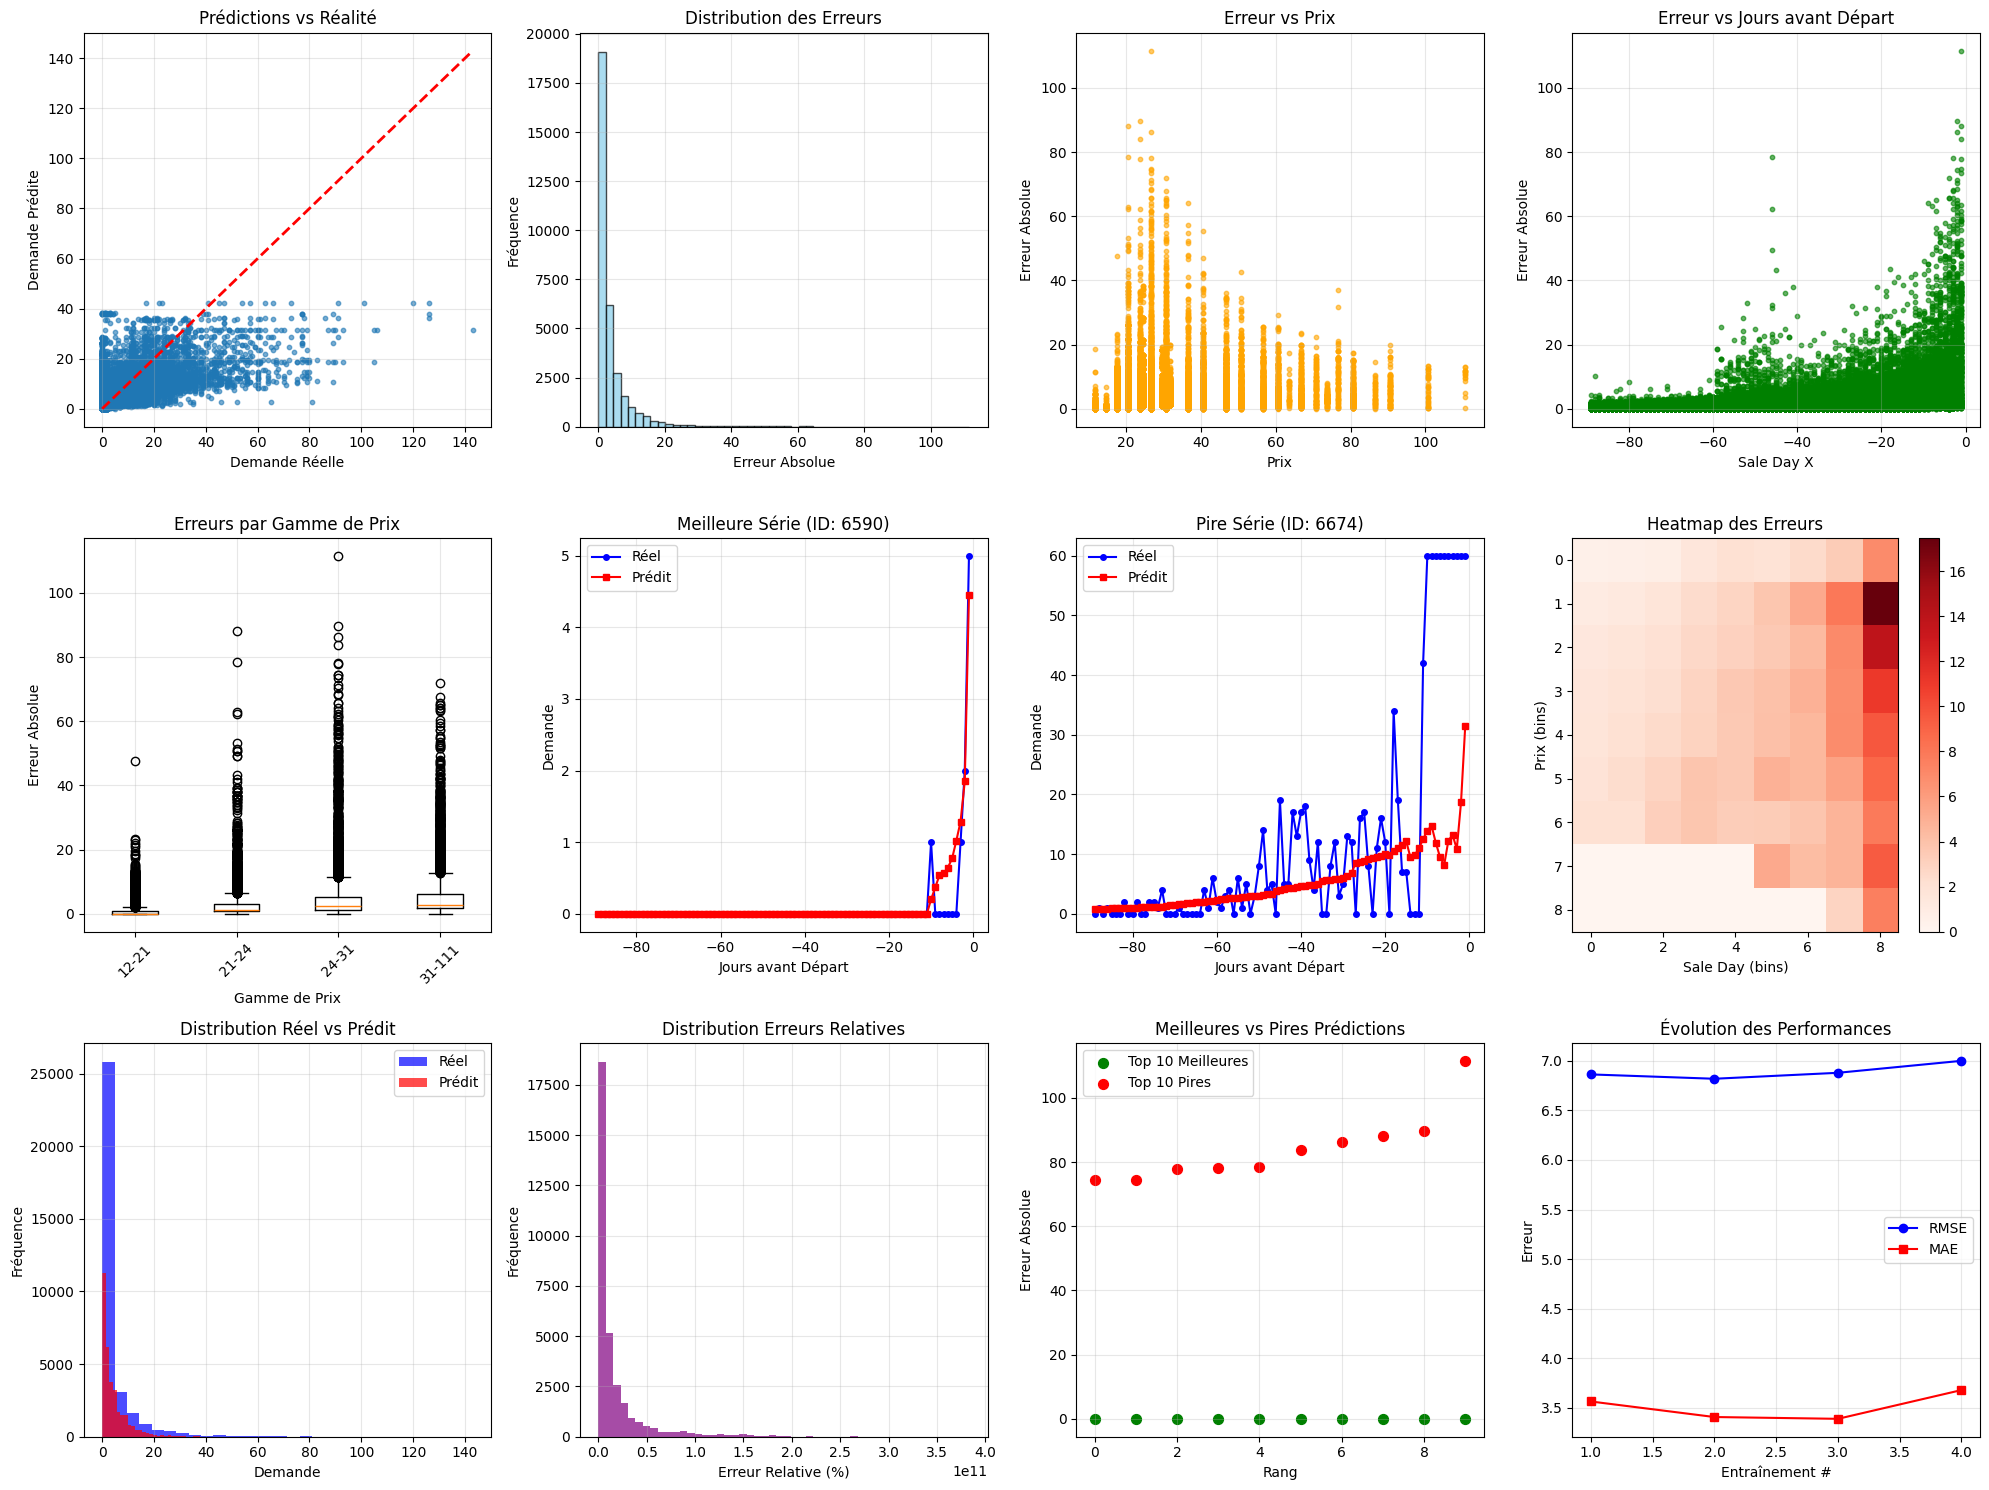

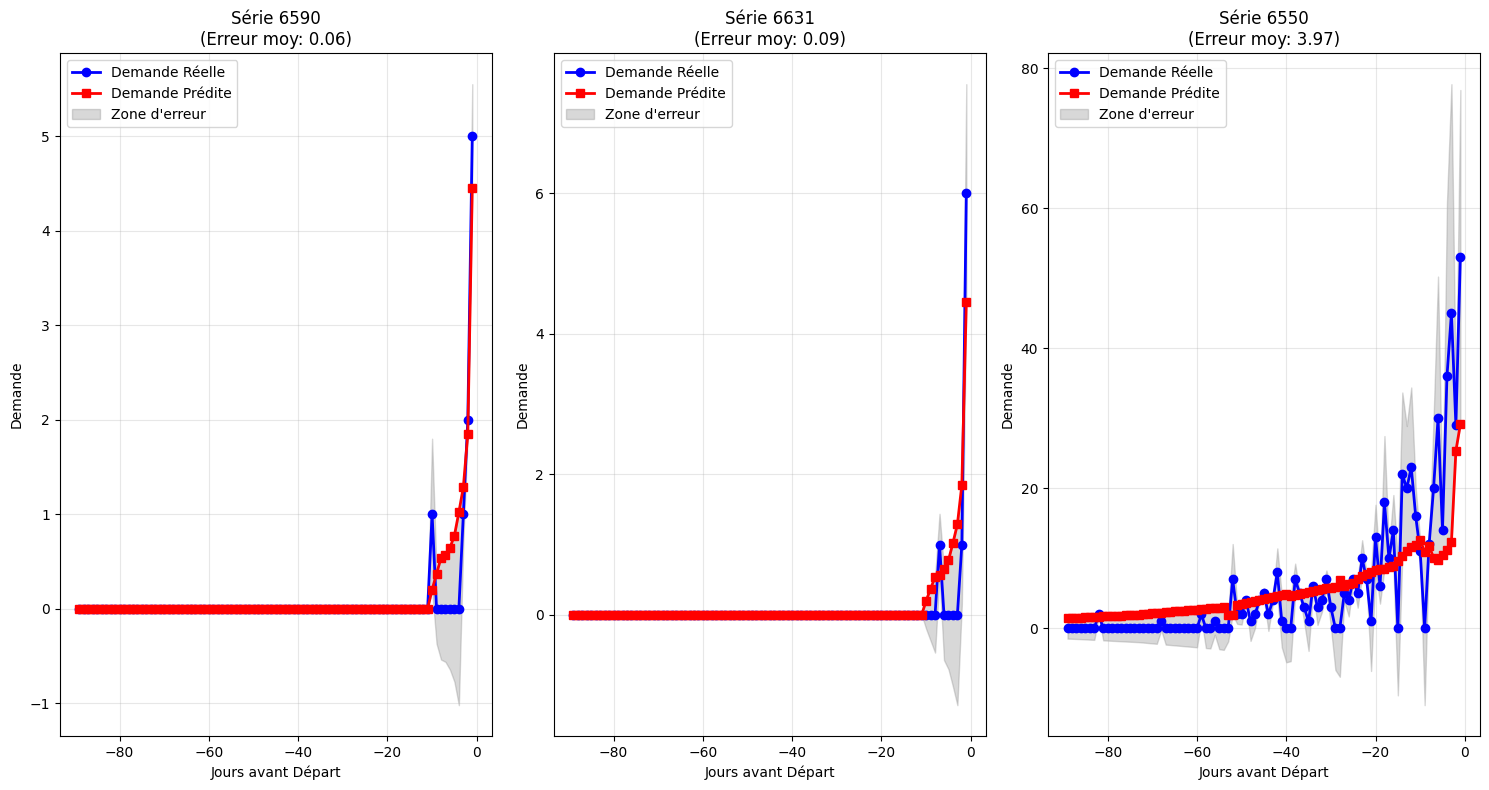

📊 Visualisations générées et sauvegardées!
📁 Fichiers créés: 'model_analysis.png' et 'time_series_examples.png'


In [75]:
# 📊 VISUALISATIONS
print(f"\n🎨 Génération des visualisations...")

# Préparer les données pour les graphiques
absolute_errors = np.abs(y_test - test_predictions)
test_df_viz = test_df.copy()
test_df_viz['predicted'] = test_predictions
test_df_viz['absolute_error'] = absolute_errors

# Figure avec plusieurs sous-graphiques
fig = plt.figure(figsize=(20, 15))

# 1. Scatter plot: Prédictions vs Valeurs réelles
plt.subplot(3, 4, 1)
plt.scatter(y_test, test_predictions, alpha=0.6, s=10)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Demande Réelle')
plt.ylabel('Demande Prédite')
plt.title('Prédictions vs Réalité')
plt.grid(True, alpha=0.3)

# 2. Histogramme des erreurs
plt.subplot(3, 4, 2)
plt.hist(absolute_errors, bins=50, alpha=0.7, color='skyblue', edgecolor='black')
plt.xlabel('Erreur Absolue')
plt.ylabel('Fréquence')
plt.title('Distribution des Erreurs')
plt.grid(True, alpha=0.3)

# 3. Erreurs vs Prix
plt.subplot(3, 4, 3)
plt.scatter(X_test[:, 0], absolute_errors, alpha=0.6, s=10, color='orange')
plt.xlabel('Prix')
plt.ylabel('Erreur Absolue')
plt.title('Erreur vs Prix')
plt.grid(True, alpha=0.3)

# 4. Erreurs vs Sale_day
plt.subplot(3, 4, 4)
plt.scatter(X_test[:, 1], absolute_errors, alpha=0.6, s=10, color='green')
plt.xlabel('Sale Day X')
plt.ylabel('Erreur Absolue')
plt.title('Erreur vs Jours avant Départ')
plt.grid(True, alpha=0.3)

# 5. Boxplot des erreurs par gamme de prix
plt.subplot(3, 4, 5)
price_quartiles = np.percentile(X_test[:, 0], [0, 25, 50, 75, 100])
price_groups = []
price_labels = []
for i in range(len(price_quartiles)-1):
    mask = (X_test[:, 0] >= price_quartiles[i]) & (X_test[:, 0] < price_quartiles[i+1])
    if np.sum(mask) > 0:
        price_groups.append(absolute_errors[mask])
        price_labels.append(f'{price_quartiles[i]:.0f}-{price_quartiles[i+1]:.0f}')

plt.boxplot(price_groups, labels=price_labels)
plt.xlabel('Gamme de Prix')
plt.ylabel('Erreur Absolue')
plt.title('Erreurs par Gamme de Prix')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

# 6. Série temporelle - Meilleure série
plt.subplot(3, 4, 6)
if 'time_series_id' in test_df.columns:
    # Trouver la meilleure série
    series_performance = test_df_viz.groupby('time_series_id')['absolute_error'].mean()
    best_series_id = series_performance.idxmin()
    best_series_data = test_df_viz[test_df_viz['time_series_id'] == best_series_id].sort_values('sale_day_x')
    
    plt.plot(best_series_data['sale_day_x'], best_series_data['demand'], 'b-o', label='Réel', markersize=4)
    plt.plot(best_series_data['sale_day_x'], best_series_data['predicted'], 'r-s', label='Prédit', markersize=4)
    plt.xlabel('Jours avant Départ')
    plt.ylabel('Demande')
    plt.title(f'Meilleure Série (ID: {best_series_id})')
    plt.legend()
    plt.grid(True, alpha=0.3)

# 7. Série temporelle - Pire série
plt.subplot(3, 4, 7)
if 'time_series_id' in test_df.columns:
    # Trouver la pire série
    worst_series_id = series_performance.idxmax()
    worst_series_data = test_df_viz[test_df_viz['time_series_id'] == worst_series_id].sort_values('sale_day_x')
    
    plt.plot(worst_series_data['sale_day_x'], worst_series_data['demand'], 'b-o', label='Réel', markersize=4)
    plt.plot(worst_series_data['sale_day_x'], worst_series_data['predicted'], 'r-s', label='Prédit', markersize=4)
    plt.xlabel('Jours avant Départ')
    plt.ylabel('Demande')
    plt.title(f'Pire Série (ID: {worst_series_id})')
    plt.legend()
    plt.grid(True, alpha=0.3)

# 8. Heatmap: Erreur moyenne par Prix vs Sale_day
plt.subplot(3, 4, 8)
# Créer des bins pour prix et sale_day
price_bins = np.linspace(X_test[:, 0].min(), X_test[:, 0].max(), 10)
saleday_bins = np.linspace(X_test[:, 1].min(), X_test[:, 1].max(), 10)

# Calculer l'erreur moyenne dans chaque cellule
error_matrix = np.zeros((len(price_bins)-1, len(saleday_bins)-1))
for i in range(len(price_bins)-1):
    for j in range(len(saleday_bins)-1):
        mask = ((X_test[:, 0] >= price_bins[i]) & (X_test[:, 0] < price_bins[i+1]) &
                (X_test[:, 1] >= saleday_bins[j]) & (X_test[:, 1] < saleday_bins[j+1]))
        if np.sum(mask) > 0:
            error_matrix[i, j] = np.mean(absolute_errors[mask])

im = plt.imshow(error_matrix, cmap='Reds', aspect='auto')
plt.colorbar(im)
plt.xlabel('Sale Day (bins)')
plt.ylabel('Prix (bins)')
plt.title('Heatmap des Erreurs')

# 9. Distribution des demandes réelles vs prédites
plt.subplot(3, 4, 9)
plt.hist(y_test, bins=30, alpha=0.7, label='Réel', color='blue')
plt.hist(test_predictions, bins=30, alpha=0.7, label='Prédit', color='red')
plt.xlabel('Demande')
plt.ylabel('Fréquence')
plt.title('Distribution Réel vs Prédit')
plt.legend()
plt.grid(True, alpha=0.3)

# 10. Erreurs relatives
plt.subplot(3, 4, 10)
relative_errors = absolute_errors / (y_test + 1e-8) * 100
plt.hist(relative_errors, bins=50, alpha=0.7, color='purple')
plt.xlabel('Erreur Relative (%)')
plt.ylabel('Fréquence')
plt.title('Distribution Erreurs Relatives')
plt.grid(True, alpha=0.3)

# 11. Top 10 meilleures vs pires prédictions
plt.subplot(3, 4, 11)
best_10 = np.argsort(absolute_errors)[:10]
worst_10 = np.argsort(absolute_errors)[-10:]

plt.scatter(range(10), absolute_errors[best_10], color='green', label='Top 10 Meilleures', s=50)
plt.scatter(range(10), absolute_errors[worst_10], color='red', label='Top 10 Pires', s=50)
plt.xlabel('Rang')
plt.ylabel('Erreur Absolue')
plt.title('Meilleures vs Pires Prédictions')
plt.legend()
plt.grid(True, alpha=0.3)

# 12. Évolution historique des performances (si fichier existe)
plt.subplot(3, 4, 12)
if os.path.exists("training_results.csv"):
    history = pd.read_csv("training_results.csv")
    plt.plot(history.index + 1, history['rmse'], 'b-o', label='RMSE', markersize=6)
    plt.plot(history.index + 1, history['mae'], 'r-s', label='MAE', markersize=6)
    plt.xlabel('Entraînement #')
    plt.ylabel('Erreur')
    plt.title('Évolution des Performances')
    plt.legend()
    plt.grid(True, alpha=0.3)
else:
    plt.text(0.5, 0.5, 'Pas d\'historique\ndisponible', 
             horizontalalignment='center', verticalalignment='center',
             transform=plt.gca().transAxes, fontsize=12)
    plt.title('Évolution des Performances')

plt.tight_layout()
plt.savefig('model_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# Graphique bonus : Série temporelle aléatoire avec comparaison
if 'time_series_id' in test_df.columns:
    plt.figure(figsize=(15, 8))
    
    # Sélectionner 3 séries aléatoires
    unique_series = test_df_viz['time_series_id'].unique()
    random_series = np.random.choice(unique_series, min(3, len(unique_series)), replace=False)
    
    for i, series_id in enumerate(random_series):
        plt.subplot(1, 3, i+1)
        series_data = test_df_viz[test_df_viz['time_series_id'] == series_id].sort_values('sale_day_x')
        
        plt.plot(series_data['sale_day_x'], series_data['demand'], 'b-o', 
                label='Demande Réelle', markersize=6, linewidth=2)
        plt.plot(series_data['sale_day_x'], series_data['predicted'], 'r-s', 
                label='Demande Prédite', markersize=6, linewidth=2)
        plt.fill_between(series_data['sale_day_x'], 
                        series_data['demand'] - series_data['absolute_error'],
                        series_data['demand'] + series_data['absolute_error'],
                        alpha=0.3, color='gray', label='Zone d\'erreur')
        
        plt.xlabel('Jours avant Départ')
        plt.ylabel('Demande')
        plt.title(f'Série {series_id}\n(Erreur moy: {series_data["absolute_error"].mean():.2f})')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('time_series_examples.png', dpi=300, bbox_inches='tight')
    plt.show()

print("📊 Visualisations générées et sauvegardées!")
print("📁 Fichiers créés: 'model_analysis.png' et 'time_series_examples.png'")